<p class="hz-kicker">Week 2 · Live session</p>

# From raw data to insight

Altamar's booking file is full of copies, misspellings and impossible values, and every summary built on it is wrong. Today you find each problem, clean it with a decision you can defend, and turn the clean data into tables, charts and three findings a general manager can act on.

<ul class="hz-lesson-meta"><li>4 hours</li><li>9 ideas</li><li>Runs in your browser</li><li>Case: clean data and patterns</li></ul>

**Run this cell first.** You don't need to read it: it loads the tools and a few lists the session uses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
HOTELS = ["Santiago", "Viña del Mar", "Puerto Varas"]
ROOMS = ["Standard", "Superior", "Suite"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## <span class="hz-step-n">01</span> Previously at Altamar

Last week you joined Altamar's management team and opened the raw booking file: 6,060 bookings at three hotels. Two questions are waiting:

- **Revenue management:** what nightly rate (`adr`) can we charge?
- **Operations:** which bookings will cancel?

Managers don't read 6,060 rows. They decide with **summaries**: an average rate per hotel, a cancellation rate per channel. So the summaries must be right. The cell below asks the raw file the first question any manager asks: *what is our average rate at each hotel?*

In [2]:
raw = pd.read_csv(DATA + "altamar_bookings.csv")
print(f"Raw file: {len(raw):,} bookings, {raw.shape[1]} columns\n")

# The first summary a manager asks for: the average nightly rate by hotel
raw.groupby("hotel")["adr"].mean().round(1)

Raw file: 6,060 bookings, 20 columns



hotel
Pto. Varas      148.5
Puerto Varas    158.0
SANTIAGO        101.9
Santiago        100.3
VIÑA DEL MAR    138.3
Vina del Mar    137.4
Viña del Mar    140.4
Name: adr, dtype: float64

**Seven hotels, for a group that owns three.** `SANTIAGO`, `Vina del Mar` and `Pto. Varas` are the same hotels typed differently by different systems, and pandas counts each spelling as a separate hotel. The averages are wrong too: hidden inside are free rooms and rates with an extra zero.

Today, in order:

1. look inside the table and pick exactly the rows you need,
2. **audit** the file: find every problem with code,
3. **clean** it, writing down each decision,
4. summarize it with tables and charts that answer questions,
5. write three findings for the general manager.

## <span class="hz-step-n">02</span> Anatomy of a table

`raw` is a **DataFrame**, pandas' word for a table:

- each **row** is one booking, labelled by the **index** (0, 1, 2… by default);
- each **column** is one fact about the booking: hotel, nights, rate;
- each column has a **type**: `object` for text, `int64` for whole numbers, `float64` for numbers with decimals.

One column on its own is a **Series**: one fact for every booking. Click the parts of the table below to see where each lives and what pandas gives back.

<div class="hz-widget" data-widget="df-anatomy">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

`head()` shows the first rows. Look at a few bookings before trusting any number.

In [3]:
raw.head()

,booking_id,hotel,booking_date,arrival_date,lead_time_days,nights,weekend_nights,adults,children,room_type,customer_type,channel,deposit,repeat_guest,previous_cancellations,special_requests,parking,country,adr,canceled
0,AH-200974,Viña del Mar,2023-10-15,2024-01-15,92,3,0,2,2.0,Superior,Leisure,Online travel agency,Non-refundable,0,0,2,0,Other,202.58,1
1,AH-204908,Santiago,2024-10-11,2024-10-16,5,2,0,1,0.0,Standard,Business,Online travel agency,No deposit,0,1,1,0,Chile,115.22,1
2,AH-202738,Viña del Mar,2024-07-31,2024-08-13,13,5,2,2,0.0,Standard,Leisure,Direct,Non-refundable,0,0,2,0,Chile,68.57,0
3,AH-205156,Viña del Mar,2024-02-18,2024-03-15,26,6,3,2,0.0,Superior,Leisure,Online travel agency,No deposit,0,0,2,1,Chile,133.13,0
4,AH-200450,Puerto Varas,2025-02-26,2025-04-08,41,3,0,2,2.0,Standard,Leisure,Direct,No deposit,0,0,2,0,NaN,113.35,0


`info()` lists every column with its type and how many values are **not missing**: any count below 6,060 is a column with gaps. `describe()` summarizes the numeric columns: look at the **min** and **max** rows.

In [4]:
raw.info()
raw[["lead_time_days", "nights", "adults", "adr"]].describe().round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6060 entries, 0 to 6059
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   booking_id              6060 non-null   object 
 1   hotel                   6060 non-null   object 
 2   booking_date            6060 non-null   object 
 3   arrival_date            6060 non-null   object 
 4   lead_time_days          6060 non-null   int64  
 5   nights                  6060 non-null   int64  
 6   weekend_nights          6060 non-null   int64  
 7   adults                  6060 non-null   int64  
 8   children                5999 non-null   float64
 9   room_type               6060 non-null   object 
 10  customer_type           6060 non-null   object 
 11  channel                 6060 non-null   object 
 12  deposit                 6060 non-null   object 
 13  repeat_guest            6060 non-null   int64  
 14  previous_cancellations  6060 non-null   

,lead_time_days,nights,adults,adr
count,6060.0,6060.0,6060.0,6060.0
mean,48.8,3.9,1.9,128.2
std,54.2,2.1,0.8,66.6
min,-152.0,1.0,0.0,0.0
25%,11.0,2.0,1.0,87.8
50%,30.0,3.0,2.0,113.4
75%,67.0,6.0,2.0,155.2
max,424.0,8.0,4.0,1668.1


**Read it like an auditor.** Two columns have gaps: `children` (5,999 values) and `country` (5,876). And `children` is stored as `float64`, with decimals, although nobody books 1.5 children: pandas stores a missing number as `NaN`, which only exists for decimal columns.

**Spot the dirt already.** The shortest lead time is negative (booked after arriving?), some rooms have 0 adults, the cheapest night costs 0 USD and the most expensive 1,668 USD, while three quarters of the rates are below 155 USD. `describe()` is the cheapest data-quality check there is.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "In the raw file, <code>children</code> is stored as <code>float64</code> (decimals). What does that most likely tell you?", "options": ["Some bookings really have half a child", "The column has missing values: pandas stores a missing number as NaN, which needs a decimal type", "The column is text", "Nothing: pandas always stores counts with decimals"], "answer": 1, "why": "A whole-number column with gaps becomes float64, because NaN is a decimal value. info() confirms it: 5,999 of 6,060 values are present. Section 05 fills the gaps and turns the column back into whole numbers.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Selecting and filtering

Most questions start by narrowing the table: *only Viña del Mar*, *only suites*, *only bookings made 90 or more days ahead*.

A comparison on a column, like `raw["hotel"] == "Viña del Mar"`, gives a **mask**: one True or False per booking. Put the mask inside `raw[...]` and only the True rows survive. Combine masks with `&` (and) and `|` (or), with **each condition in its own parentheses**.

<div class="hz-widget" data-widget="mask-filter">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

Three masks, one at a time, then the revenue manager's real request: **Viña del Mar bookings made 90+ days ahead**, compared with the rest of Viña. `len()` counts the rows that survive.

In [5]:
is_vina = raw["hotel"] == "Viña del Mar"
is_suite = raw["room_type"] == "Suite"
is_early = raw["lead_time_days"] >= 90
print(f"Viña del Mar: {is_vina.sum():,}   Suites: {is_suite.sum():,}   Made 90+ days ahead: {is_early.sum():,}\n")

vina_early = raw[is_vina & is_early]
vina_late = raw[is_vina & ~is_early]          # ~ means "not"
print(f"Viña del Mar, 90+ days ahead: {len(vina_early):,} bookings, average rate USD {vina_early['adr'].mean():.0f}")
print(f"Viña del Mar, closer in:      {len(vina_late):,} bookings, average rate USD {vina_late['adr'].mean():.0f}")
print(f"Viña del Mar OR 90+ days:     {(is_vina | is_early).sum():,} bookings")

Viña del Mar: 1,987   Suites: 606   Made 90+ days ahead: 1,034

Viña del Mar, 90+ days ahead: 428 bookings, average rate USD 130
Viña del Mar, closer in:      1,559 bookings, average rate USD 143
Viña del Mar OR 90+ days:     2,593 bookings


Early beach bookings pay about 13 USD less a night: early-bird discounts. **Watch out:** the filter only finds the exact text `"Viña del Mar"`. The cell below counts the bookings our filter missed because they were typed differently. The data is lying to our filters, which is why we audit next.

In [6]:
spellings = ["Viña del Mar", "Vina del Mar", "VIÑA DEL MAR"]
all_vina = raw["hotel"].isin(spellings)       # isin: "one of these values"
print(f"Exact spelling only: {is_vina.sum():,}   Any spelling: {all_vina.sum():,}   Missed: {all_vina.sum() - is_vina.sum()}")

Exact spelling only: 1,987   Any spelling: 2,059   Missed: 72


Sometimes you need **one booking** by its ID. Make `booking_id` the index, and `.loc` finds rows by their **label**; `.iloc` counts **positions** 0, 1, 2… like a list. Most of the time you will filter with masks; the explainer shows the difference for when you meet `.loc` and `.iloc` in the toolkit.

<div class="hz-widget" data-widget="loc-iloc">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

In [7]:
bookings = raw.set_index("booking_id")
print(bookings.loc["AH-204908", ["hotel", "room_type", "adr"]])   # by label: one booking
print()
print(bookings.iloc[0:3, 0:3])                                    # by position: first 3 rows, first 3 columns

hotel        Santiago
room_type    Standard
adr            115.22
Name: AH-204908, dtype: object

                   hotel booking_date arrival_date
booking_id                                        
AH-200974   Viña del Mar   2023-10-15   2024-01-15
AH-204908       Santiago   2024-10-11   2024-10-16
AH-202738   Viña del Mar   2024-07-31   2024-08-13


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "What does <code>(raw['hotel'] == 'Viña del Mar') | (raw['lead_time_days'] &gt;= 90)</code> keep when you put it inside <code>raw[...]</code>?", "options": ["Only Viña del Mar bookings made 90+ days ahead", "Every Viña del Mar booking, plus every booking made 90+ days ahead at any hotel", "Bookings that are neither at Viña del Mar nor made early", "An error: you cannot combine two conditions"], "answer": 1, "why": "<code>|</code> means OR: a row survives if at least one condition is True. The early beach bookings need <code>&amp;</code>, AND, which keeps a row only when both are True.", "code": false}</script>
</div>

## <span class="hz-step-n">04</span> The data quality audit

An audit asks one question per kind of problem, answers it with code, and writes down **why it matters for a decision**. Run every check on the raw file *before* changing anything, so you know what you are about to fix:

1. Are there **duplicate** bookings?
2. Are hotels and channels **spelled consistently**?
3. Are there **impossible rates**?
4. Are there **impossible lead times or rooms without adults**?
5. What is **missing**?

**Checks 1 and 2.** `duplicated()` marks a row identical, column by column, to an earlier one; `value_counts()` lists every distinct text and how often it appears. At the bottom, one booking that was loaded twice.

In [8]:
print(f"Exact duplicate rows: {raw.duplicated().sum()}\n")
print(raw["hotel"].value_counts(), "\n")
print(raw["channel"].value_counts())
raw.loc[raw["booking_id"] == "AH-200037", ["booking_id", "hotel", "arrival_date", "adr", "canceled"]]

Exact duplicate rows: 60

hotel
Santiago        2378
Viña del Mar    1987
Puerto Varas    1439
SANTIAGO         110
Pto. Varas        74
VIÑA DEL MAR      37
Vina del Mar      35
Name: count, dtype: int64 

channel
Online travel agency    2506
Direct                  1696
Corporate                910
Travel agent             814
online travel agency      49
Online Travel Agency      48
OTA                       37
Name: count, dtype: int64


,booking_id,hotel,arrival_date,adr,canceled
893,AH-200037,Santiago,2025-11-10,96.22,1
3697,AH-200037,Santiago,2025-11-10,96.22,1


Three hotels written seven ways; four channels written seven ways (`OTA`, `online travel agency` and `Online Travel Agency` are all the online travel agency).

**Checks 3 and 4, impossible values.** A rate of 0 USD is a complimentary room, and nothing at Altamar costs 1,000 USD a night. Nobody books after arriving, and every room needs an adult. The table lists the suspicious rates.

In [9]:
free = raw["adr"] <= 0
huge = raw["adr"] >= 1000
negative = raw["lead_time_days"] < 0
no_adults = raw["adults"] <= 0
print(f"Rates of 0 USD: {free.sum()}    Rates of 1,000 USD or more: {huge.sum()}")
print(f"Negative lead times: {negative.sum()}    Bookings with 0 adults: {no_adults.sum()}")
raw.loc[huge, ["booking_id", "hotel", "room_type", "adr"]]

Rates of 0 USD: 12    Rates of 1,000 USD or more: 6
Negative lead times: 10    Bookings with 0 adults: 8


,booking_id,hotel,room_type,adr
154,AH-203052,Viña del Mar,Standard,1335.7
249,AH-201235,Santiago,Superior,1022.8
1715,AH-203552,Santiago,Standard,1044.6
3955,AH-205197,Santiago,Superior,1417.7
4378,AH-200796,Viña del Mar,Standard,1200.7
4945,AH-200784,Puerto Varas,Standard,1668.1


A superior room in Santiago at 1,022.80 USD is almost surely 102.28 typed with an extra zero. **Check 5, missing values,** goes straight into the audit table with all the other counts and the reason each one matters. This table is what you show a manager before showing any result.

In [10]:
audit = pd.DataFrame([
    ["Duplicate rows", raw.duplicated().sum(), "A booking counted twice weighs double in every average"],
    ["Hotel spelled another way", (~raw["hotel"].isin(HOTELS)).sum(), "A summary by hotel lists 7 hotels instead of 3"],
    ["Channel spelled another way", raw["channel"].isin(["OTA", "online travel agency", "Online Travel Agency"]).sum(), "OTA cancellations are split across 4 labels"],
    ["Rate of 0 USD", free.sum(), "A free room is not a price: it drags the average rate down"],
    ["Rate of 1,000 USD or more", huge.sum(), "One typo moves a hotel's average by several dollars"],
    ["Negative lead time", negative.sum(), "Booked after arrival: the dates were swapped"],
    ["Booking with 0 adults", no_adults.sum(), "A room needs a guest: the record is broken"],
    ["Missing children", raw["children"].isna().sum(), "Rows with gaps break some calculations and models"],
    ["Missing country", raw["country"].isna().sum(), "Market analyses by country would silently drop them"],
], columns=["problem", "rows", "why it matters for a decision"])
audit

,problem,rows,why it matters for a decision
0,Duplicate rows,60,A booking counted twice weighs double in every average
1,Hotel spelled another way,256,A summary by hotel lists 7 hotels instead of 3
2,Channel spelled another way,134,OTA cancellations are split across 4 labels
3,Rate of 0 USD,12,A free room is not a price: it drags the average rate down
4,"Rate of 1,000 USD or more",6,One typo moves a hotel's average by several dollars
5,Negative lead time,10,Booked after arrival: the dates were swapped
6,Booking with 0 adults,8,A room needs a guest: the record is broken
7,Missing children,61,Rows with gaps break some calculations and models
8,Missing country,184,Market analyses by country would silently drop them


☕ **Break.** In the second block you clean the file, check the result against Altamar's published clean file, and turn it into tables, charts and findings.

## <span class="hz-step-n">05</span> Cleaning with decisions you can defend

Every problem needs a **decision**, and every decision needs a reason a manager would accept:

| Problem | Decision | Why |
|---|---|---|
| Duplicates | Drop the copy | One booking, counted once |
| Spellings | Map to the official names | Same hotel, same label |
| Rate of 0 or ≥ 1,000 USD | Drop the booking | Not a real price; guessing would invent one |
| Negative lead time, 0 adults | Drop the booking | Impossible, and only 18 rows |
| Missing children | Fill with 0 | Three in four bookings have none |
| Missing country | New label `Unknown` | Honest: we don't invent a country |

Watch the pipeline first, then run it step by step.

<div class="hz-widget" data-widget="cleaning-audit">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

Each step changes `df` (a copy of the raw file) and adds one line to `log`, the **cleaning log**. Step 1: duplicates.

In [11]:
df = raw.copy()
log = []    # one line per decision: problem, decision, rows affected

def record(problem, decision, rows):
    log.append({"problem": problem, "decision": decision, "rows affected": int(rows)})
    print(f"{problem}: {rows:,} rows → {decision}")

before = len(df)
df = df.drop_duplicates().copy()
record("Exact duplicate rows", "Dropped the copy, kept the first", before - len(df))

Exact duplicate rows: 60 rows → Dropped the copy, kept the first


Step 2: labels. A dictionary says which spelling becomes which official name. For channels, lower case first, then `ota` becomes the full name, then a capital first letter.

In [12]:
HOTEL_FIX = {"SANTIAGO": "Santiago", "Vina del Mar": "Viña del Mar", "VIÑA DEL MAR": "Viña del Mar", "Pto. Varas": "Puerto Varas"}
fixed = df["hotel"].replace(HOTEL_FIX)
record("Hotel written 4 other ways", "Mapped to the 3 official names", (fixed != df["hotel"]).sum())
df["hotel"] = fixed

fixed = df["channel"].str.lower().replace({"ota": "online travel agency"}).str.capitalize()
record("Channel written 3 other ways", "Lower case, OTA to the full name", (fixed != df["channel"]).sum())
df["channel"] = fixed
print(f"\nHotels now: {df['hotel'].nunique()}   Channels now: {df['channel'].nunique()}")

Hotel written 4 other ways: 250 rows → Mapped to the 3 official names
Channel written 3 other ways: 134 rows → Lower case, OTA to the full name

Hotels now: 3   Channels now: 4


Steps 3 and 4: impossible values. We keep rates above 0 and below 1,000 USD, then drop the impossible bookings. (We could rebuild the 10 lead times from the two dates, but with 10 rows out of 6,000 the cleaner decision is to drop them and say so.)

In [13]:
record("Rate of 0 USD (complimentary room)", "Dropped: not a price", (df["adr"] <= 0).sum())
record("Rate of 1,000 USD or more (extra zero)", "Dropped: not a real price", (df["adr"] >= 1000).sum())
df = df[(df["adr"] > 0) & (df["adr"] < 1000)]

record("Negative lead time (dates swapped)", "Dropped the booking", (df["lead_time_days"] < 0).sum())
df = df[df["lead_time_days"] >= 0]
record("Booking with 0 adults", "Dropped the booking", (df["adults"] <= 0).sum())
df = df[df["adults"] > 0]

Rate of 0 USD (complimentary room): 12 rows → Dropped: not a price
Rate of 1,000 USD or more (extra zero): 6 rows → Dropped: not a real price
Negative lead time (dates swapped): 10 rows → Dropped the booking
Booking with 0 adults: 8 rows → Dropped the booking


Step 5: missing values. `fillna` fills the gaps; `astype("int64")` turns `children` back into whole numbers.

In [14]:
share_none = (df["children"].dropna() == 0).mean()
record("Missing children", f"Filled with 0 ({share_none:.0%} of bookings have none)", df["children"].isna().sum())
df["children"] = df["children"].fillna(0).astype("int64")

record("Missing country", 'New category "Unknown"', df["country"].isna().sum())
df["country"] = df["country"].fillna("Unknown")
df = df.reset_index(drop=True)          # number the rows 0, 1, 2... again

Missing children: 60 rows → Filled with 0 (76% of bookings have none)
Missing country: 180 rows → New category "Unknown"


Last check: does our cleaning give **exactly** the clean file that sessions 3 to 6 start from? `assert_frame_equal` compares every value and every type, and stops with an error at the first difference. Below it, the log becomes the **cleaning table** your manager, and your case, need to see.

In [15]:
published = pd.read_csv(DATA + "altamar_bookings_clean.csv")
pd.testing.assert_frame_equal(df, published)
print("Matches the published clean file")
print(f"Bookings: {len(raw):,} → {len(df):,} ({len(raw) - len(df)} removed), missing values left: {df.isna().sum().sum()}")

cleaning_log = pd.DataFrame(log)
cleaning_log

Matches the published clean file
Bookings: 6,060 → 5,964 (96 removed), missing values left: 0


,problem,decision,rows affected
0,Exact duplicate rows,"Dropped the copy, kept the first",60
1,Hotel written 4 other ways,Mapped to the 3 official names,250
2,Channel written 3 other ways,"Lower case, OTA to the full name",134
3,Rate of 0 USD (complimentary room),Dropped: not a price,12
4,"Rate of 1,000 USD or more (extra zero)",Dropped: not a real price,6
5,Negative lead time (dates swapped),Dropped the booking,10
6,Booking with 0 adults,Dropped the booking,8
7,Missing children,Filled with 0 (76% of bookings have none),60
8,Missing country,"New category ""Unknown""",180


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A colleague suggests replacing the 12 complimentary rates (0 USD) with the hotel's average rate, instead of dropping them. Why does Altamar drop them?", "options": ["Because pandas cannot replace zeros", "Because a free room is not a price: an invented rate would put prices in the file that no guest paid", "Because 12 rows are too many to keep", "Because the average rate cannot be computed while zeros exist"], "answer": 1, "why": "The question is what guests pay. A complimentary room says nothing about that, and a made-up average would make the file look more certain than it is. For other questions, like how many rooms were occupied, you might keep them: the decision depends on the question.", "code": false}</script>
</div>

## <span class="hz-step-n">06</span> Summaries that answer questions

Clean data at last. Most management questions have the same shape: *what is the average X for each Y?* That is a **groupby**: **split** the bookings by Y, **apply** a calculation inside each group, **combine** the answers into one small table.

<div class="hz-widget" data-widget="groupby">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

First the average nightly rate at each hotel, now with three hotels (`count` says how many bookings stand behind each average). Then a **pivot table**, a groupby with two keys, one on the rows and one on the columns: average rate by hotel **and** room type.

In [16]:
rate_by_hotel = df.groupby("hotel")["adr"].agg(["count", "mean", "median"]).round(1)
print(rate_by_hotel.loc[HOTELS], "\n")

rate_table = df.pivot_table(index="hotel", columns="room_type", values="adr", aggfunc="mean")
rate_table.loc[HOTELS, ROOMS].round(0)

              count   mean  median
hotel                             
Santiago       2449   99.4    93.3
Viña del Mar   2022  139.8   130.6
Puerto Varas   1493  156.5   148.8 



room_type,Standard,Superior,Suite
hotel,,,
Santiago,85.0,109.0,156.0
Viña del Mar,117.0,154.0,232.0
Puerto Varas,133.0,171.0,257.0


Now operations. `canceled` is 1 for a cancelled booking and 0 otherwise, so its **mean** in a group is the share that cancelled: the **cancellation rate**.

In [17]:
print(f"Overall cancellation rate: {df['canceled'].mean():.1%}\n")
cancel_by_channel = df.groupby("channel")["canceled"].mean().sort_values()
for channel, rate in cancel_by_channel.items():
    print(f"{channel:<22} {rate:.1%}")

Overall cancellation rate: 33.7%

Corporate              15.6%
Direct                 29.4%
Travel agent           35.5%
Online travel agency   42.2%


The same rate by channel **and** customer type, in percent. Empty cells (`NaN`) are combinations that don't exist: groups don't book through the corporate channel.

In [18]:
cancel_table = df.pivot_table(index="channel", columns="customer_type", values="canceled", aggfunc="mean")
(cancel_table * 100).round(1)

customer_type,Business,Group,Leisure
channel,,,
Corporate,15.6,NaN,NaN
Direct,14.8,43.2,33.3
Online travel agency,17.4,62.8,44.6
Travel agent,NaN,37.7,31.0


Last summary: **when** do guests arrive? We add the arrival month as a new column and count bookings per month and hotel with `crosstab`, a pivot table that counts.

In [19]:
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month
arrivals = pd.crosstab(df["arrival_month"], df["hotel"])[HOTELS]
arrivals.index = MONTHS
arrivals.T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
hotel,,,,,,,,,,,,
Santiago,141,91,211,202,228,219,187,216,233,267,271,183
Viña del Mar,459,369,180,92,88,83,84,82,106,123,143,213
Puerto Varas,249,230,116,76,60,66,200,88,72,84,107,145


**Business takeaway:** Viña del Mar receives more than five times as many arrivals in January (459) as in August (82); Santiago is busiest from September to November. Each hotel lives on its own calendar.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "<code>df.groupby('channel')['canceled'].mean()</code> gives 0.422 for online travel agencies. What does 0.422 mean?", "options": ["0.422 bookings were cancelled", "42.2% of online travel agency bookings were cancelled", "Online travel agencies represent 42.2% of all cancellations", "The average booking was 42.2% cancelled"], "answer": 1, "why": "canceled is 1 or 0, so its mean inside a group is the share of 1s: the cancellation rate of that channel. The share of all cancellations that come from OTAs is a different number: it also depends on how many bookings each channel brings.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> Charts that answer questions

A table convinces an analyst; a chart convinces a meeting. The rule: **start from the question, then pick the chart.**

- how one number spreads → **histogram**
- a number compared across categories → **box plot**
- a rate per category → **bar chart**
- a number across time → **line chart**, one line per group

Every chart gets a title, axes in plain English, and **one sentence under it saying what it shows**.

<div class="hz-widget" data-widget="chart-chooser">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/">open this session on the course website</a> to use it.</p>
</div>

*How are our nightly rates spread out?* A histogram counts the bookings in each price range.

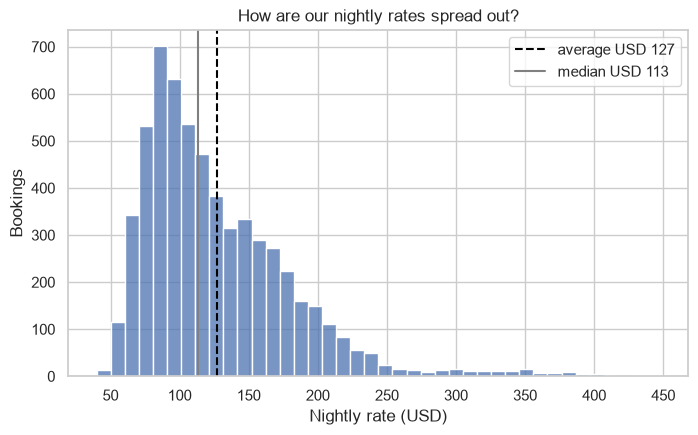

In [20]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df, x="adr", bins=40)
plt.axvline(df["adr"].mean(), color="black", linestyle="--", label=f"average USD {df['adr'].mean():.0f}")
plt.axvline(df["adr"].median(), color="grey", label=f"median USD {df['adr'].median():.0f}")
plt.title("How are our nightly rates spread out?")
plt.xlabel("Nightly rate (USD)")
plt.ylabel("Bookings")
plt.legend()
plt.show()

**What it shows:** most nights sell between 80 and 160 USD, with a long tail to the right of expensive nights (suites, peak season at the beach). The tail pulls the average (127 USD) above the median (113 USD), the rate of the typical booking.

*Do rates differ by room type?* A box plot per room type.

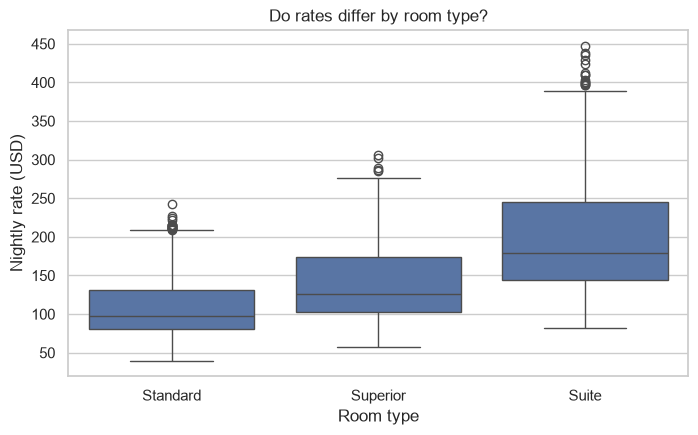

In [21]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(df, x="room_type", y="adr", order=ROOMS)
plt.title("Do rates differ by room type?")
plt.xlabel("Room type")
plt.ylabel("Nightly rate (USD)")
plt.show()

**What it shows:** the median climbs from about 98 USD for a standard room to 126 for a superior and 179 for a suite. The boxes overlap: a suite in Santiago's low season can cost less than a standard room at the beach in January. The room matters, but so do the hotel and the month.

*Which channel cancels most?* A bar chart of the cancellation rate: the mean of `canceled` in each channel.

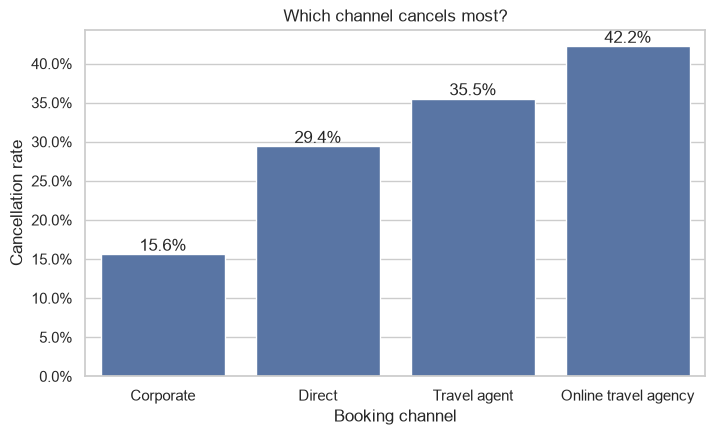

In [22]:
order = cancel_by_channel.index      # sorted from lowest to highest rate
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(df, x="channel", y="canceled", order=order, errorbar=None)
ax.bar_label(ax.containers[0], fmt="{:.1%}")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.title("Which channel cancels most?")
plt.xlabel("Booking channel")
plt.ylabel("Cancellation rate")
plt.show()

**What it shows:** 42.2% of online travel agency bookings cancel, almost three times the 15.6% of corporate bookings. For operations, a room sold through an OTA is a much less certain room.

*Does each hotel have its own seasons?* This is the key chart of the week: the average rate by arrival month, **one line per hotel**.

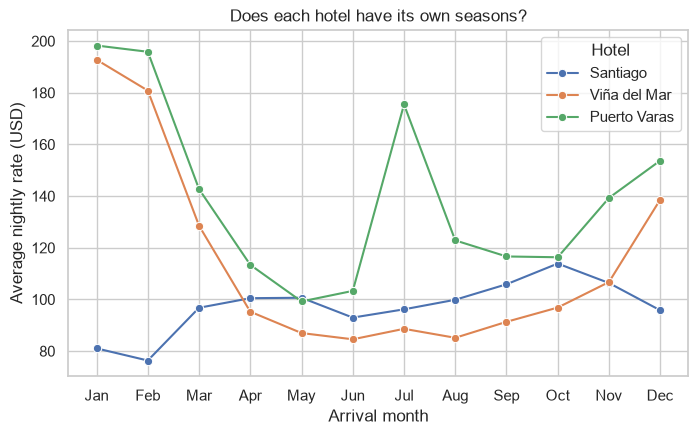

In [23]:
plt.figure(figsize=(8, 4.5))
sns.lineplot(df, x="arrival_month", y="adr", hue="hotel", hue_order=HOTELS, errorbar=None, marker="o")
plt.xticks(range(1, 13), MONTHS)
plt.title("Does each hotel have its own seasons?")
plt.xlabel("Arrival month")
plt.ylabel("Average nightly rate (USD)")
plt.legend(title="Hotel")
plt.show()

**What it shows:** three hotels, three calendars. Viña del Mar and Puerto Varas peak in January and February at about 190–200 USD; Puerto Varas peaks again in July, with the winter holidays. Santiago does the opposite: it dips in the summer (76 USD in February), when business travellers are on holiday, and peaks in October with conferences.

**Hold on to this chart.** In weeks 3 and 4 we fit straight lines; in week 5 we will see why one straight line through "month" cannot draw three different curves.

## <span class="hz-step-n">08</span> From charts to findings

A finding is not a number. It is a number **plus what it means for someone**:

> **What we see** (with the number) → **what it means for the business** → **what to check next**.

First, the numbers we will quote, printed by the code, so nobody has to trust our memory:

In [24]:
monthly = df.pivot_table(index="arrival_month", columns="hotel", values="adr", aggfunc="mean")
for hotel in HOTELS:
    peak, low = monthly[hotel].idxmax(), monthly[hotel].idxmin()
    print(f"{hotel:<13} peak {MONTHS[peak - 1]} USD {monthly[hotel].max():.0f}, low {MONTHS[low - 1]} USD {monthly[hotel].min():.0f}")
print()
print(f"Cancellation: online travel agency {cancel_by_channel['Online travel agency']:.1%}, corporate {cancel_by_channel['Corporate']:.1%}")
suite_premium = rate_table["Suite"] / rate_table["Standard"]
print("Suite rate ÷ standard rate:", ", ".join(f"{h} {suite_premium[h]:.2f}x" for h in HOTELS))

Santiago      peak Oct USD 114, low Feb USD 76
Viña del Mar  peak Jan USD 193, low Jun USD 85
Puerto Varas  peak Jan USD 198, low May USD 99

Cancellation: online travel agency 42.2%, corporate 15.6%
Suite rate ÷ standard rate: Santiago 1.82x, Viña del Mar 1.98x, Puerto Varas 1.93x


**Finding 1 · Every hotel has its own season.** Viña del Mar's average rate goes from 193 USD in January to 85 USD in June; Santiago moves the other way, from 76 USD in February to 114 in October. *For revenue management:* one price calendar for the group would undercharge the beach in summer and overcharge the city. *Next:* a rate model must let each hotel have its own months.

**Finding 2 · Online travel agency bookings cancel most.** 42.2% of them cancel, against 15.6% of corporate bookings. *For operations:* how many rooms we can oversell depends on the channel mix of each night. *Next:* week 4 predicts cancellations booking by booking.

**Finding 3 · Suites earn about twice a standard room.** The suite rate is 1.8 to 2.0 times the standard rate at every hotel. *For sales:* upgrading even a few bookings is worth testing. *Next:* how many suites go unsold?

**Correlation is not causation.** Finding 2 says OTA bookings *cancel more*; it does not say the OTA *makes* guests cancel. Look again at the cancellation table by channel and customer type from section 06:

In [25]:
print("Cancellation rate by channel, for each type of customer (%):")
(cancel_table * 100).round(1)[["Business", "Leisure"]]

Cancellation rate by channel, for each type of customer (%):


customer_type,Business,Leisure
channel,,
Corporate,15.6,NaN
Direct,14.8,33.3
Online travel agency,17.4,44.6
Travel agent,NaN,31.0


Among **business** travellers the channel barely matters: 15 to 17% cancel whichever channel they use. Most of the OTA gap comes from **who** books there (leisure guests, planning months ahead), not from the channel itself. Closing the OTA channel would not make leisure guests more reliable. Before you recommend an action, ask: *is it this factor, or something that travels with it?*

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Bookings with special requests cancel less. The marketing team proposes to ask every guest for a special request to reduce cancellations. What is the main problem?", "options": ["None: the data proves it works", "The pattern shows an association: committed guests make requests and also keep their bookings; asking for requests may not change commitment", "Special requests are too expensive", "The cancellation rate cannot be computed for special requests"], "answer": 1, "why": "Guests who already plan their stay in detail both ask for things and show up. The request is a sign of commitment, not necessarily its cause. Only a test (ask half the guests, compare) would tell whether asking changes behaviour.", "code": false}</script>
</div>

## <span class="hz-step-n">09</span> Case clinic: clean data and patterns

This week's step of the [applied case](https://hizocar.github.io/mba-business-analytics-1/case/case/) is today's session, done on your team's data. Open the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/) in Colab with your dataset and:

1. **Run section 02 Data quality audit.** Read every count it prints and decide, as a team, what each problem would do to a decision.
2. **Run section 03 Cleaning**, adjusting its ✏️ decisions, and keep its **cleaning log**: problem · decision · rows affected. Add one sentence of *why* to each line.
3. **Choose three charts** from section **04 Exploration**, one per pattern, with the question in the title and one sentence under each.

| Today with Altamar | Your case |
|---|---|
| 6,060 → 5,964 bookings, 9 problems logged | Your cleaning log |
| Rate by hotel and month; cancellation by channel | Your target by its two most interesting columns |
| Three findings for the general manager | Three patterns, each with a chart and a "so what" |

**Before next week:** finish the [lab](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Lab/) and its graded quiz. In week 3 you will build Altamar's first rate model, and see how much of the seasons above a straight line can capture.